# DL 1 — Le perceptron, premier neurone artificiel

Un réseau de neurones profond empile des millions d'unités. Chacune fait la même opération que le perceptron de Frank Rosenblatt (1958) : une somme pondérée des entrées, puis une décision. Comprendre ce neurone seul — ce qu'il calcule, comment il apprend, quand il échoue — c'est comprendre la brique de base de tout le deep learning.

On le construit ici à la main avec NumPy, sur le jeu de données Iris, puis on le compare à l'implémentation de scikit-learn. Chaque section pose une question, la teste par du code, puis lit le résultat obtenu. Les chiffres cités dans le texte sont ceux que le code affiche.

Le notebook prolonge les niveaux de machine learning : la séparation entraînement/test et le choix des métriques de [ML 1](ML_1.ipynb), la frontière de décision des [SVM](ML_0_SVM_apprentissage_supervisee.ipynb) et de [ML 4](ML_4_apprentissage_classif_supervisee.ipynb).

**Parcours** — les numéros sont ceux des sections.

| Section | Question |
|---|---|
| 1 | Que contient Iris, et quelles espèces se séparent à l'œil ? |
| 2 | Comment poser un problème binaire avec des étiquettes −1 et +1 ? |
| 3 | Que calcule un neurone artificiel, géométriquement ? |
| 4 | Comment la règle de Rosenblatt corrige-t-elle les poids, une erreur à la fois ? |
| 5 | Le perceptron converge-t-il sur setosa contre versicolor, et que vaut-il sur le test ? |
| 6 | Que change le taux d'apprentissage ? |
| 7 | Pourquoi l'ordre des exemples change-t-il la frontière apprise ? |
| 8 | Combien d'erreurs avant de converger, et pourquoi normaliser ? |
| 9 | Que se passe-t-il quand les classes se recouvrent ? |
| 10 | Pourquoi un perceptron ne sait-il pas faire un XOR ? |
| 11 | Comment passer à trois classes, et que vaut un seul découpage train/test ? |
| 12 | Que retenir pour la suite, et pour un vrai projet ? |


### Installer les dépendances

Le notebook s'exécute sur Google Colab comme en local. Toutes les données viennent de scikit-learn : aucun fichier à déposer.


In [3]:
%pip install -q numpy pandas matplotlib scikit-learn



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron as PerceptronSklearn
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

GRAINE = 655957
COULEURS = {-1: "#d1495b", 1: "#00798c"}


### Reproductibilité

Un ordinateur est déterministe : il ne tire pas de vrais nombres au hasard. Il utilise un générateur pseudo-aléatoire, qui produit toujours la même suite à partir d'un même nombre de départ, la **graine**. Fixer la graine rend un résultat identique d'une exécution à l'autre et d'une machine à l'autre : c'est la condition pour comparer deux réglages, ou ses résultats avec ceux d'un collègue.

On garde la graine du TP d'origine, 655957, dans un générateur `np.random.default_rng(GRAINE)` créé là où on en a besoin. Les fonctions de scikit-learn reçoivent leur propre `random_state`. Un générateur local évite qu'une cellule ajoutée en cours de route décale tous les tirages suivants, ce que fait une graine globale `np.random.seed`.


## 1. Le jeu de données Iris

Iris a été publié par le statisticien Ronald Fisher en 1936, à partir de mesures du botaniste Edgar Anderson. Il contient 150 fleurs de trois espèces — *Iris setosa*, *Iris versicolor*, *Iris virginica* — 50 par espèce. Chaque fleur est décrite par quatre longueurs en centimètres : longueur et largeur du sépale, longueur et largeur du pétale.

Avant tout modèle, on vérifie trois choses : la taille du tableau, le type des colonnes et l'équilibre des classes.


In [5]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
especes = iris.target_names
caracteristiques = iris.feature_names

df = pd.DataFrame(X_iris, columns=caracteristiques)
df["espece"] = pd.Categorical.from_codes(y_iris, especes)

print(f"Tableau : {X_iris.shape[0]} fleurs × {X_iris.shape[1]} caractéristiques")
print(f"Valeurs manquantes : {int(df.isna().sum().sum())}")
print("\nFleurs par espèce :")
print(df["espece"].value_counts().sort_index().to_string())
print("\nMoyenne par espèce (cm) :")
print(df.groupby("espece", observed=True).mean().round(2).to_string())


Tableau : 150 fleurs × 4 caractéristiques
Valeurs manquantes : 0

Fleurs par espèce :
espece
setosa        50
versicolor    50
virginica     50

Moyenne par espèce (cm) :
            sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
espece                                                                              
setosa                   5.01              3.43               1.46              0.25
versicolor               5.94              2.77               4.26              1.33
virginica                6.59              2.97               5.55              2.03


### Lire le tableau

150 lignes, 4 colonnes numériques, aucune valeur manquante, et exactement 50 fleurs par espèce. Le jeu est équilibré : l'exactitude (part de bonnes réponses) sera une métrique lisible, ce qui n'était pas le cas des classes déséquilibrées de ML 1.

Les moyennes donnent déjà une piste. La longueur du pétale vaut en moyenne 1,46 cm chez setosa, contre 4,26 chez versicolor et 5,55 chez virginica. La largeur du sépale, elle, varie peu d'une espèce à l'autre (3,43, 2,77, 2,97). Toutes les caractéristiques ne séparent pas aussi bien. Le graphique le montre directement.


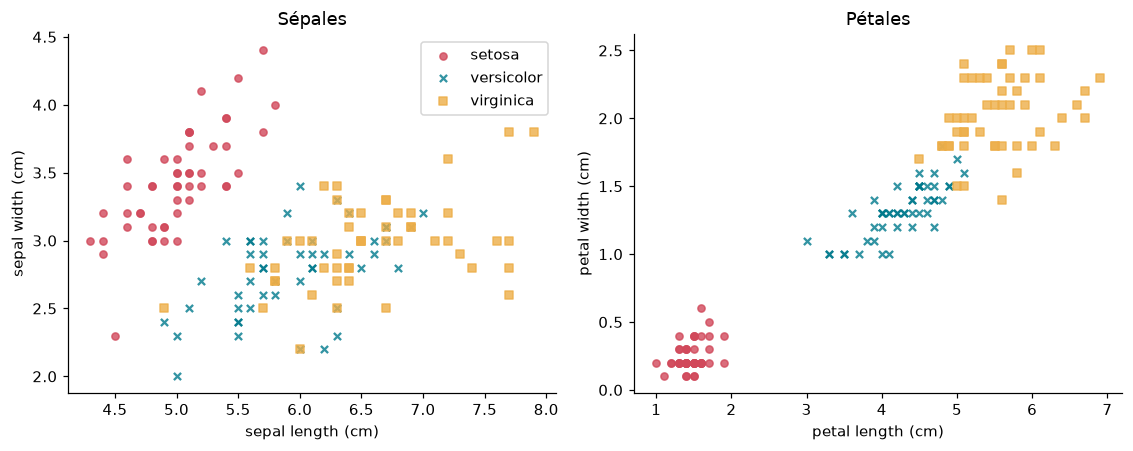

In [6]:
marqueurs = {"setosa": "o", "versicolor": "x", "virginica": "s"}
couleurs_especes = {"setosa": "#d1495b", "versicolor": "#00798c", "virginica": "#edae49"}

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
for ax, (i, j) in zip(axes, [(0, 1), (2, 3)]):
    for code_espece, nom in enumerate(especes):
        points = X_iris[y_iris == code_espece]
        ax.scatter(
            points[:, i], points[:, j], s=22, alpha=0.8,
            marker=marqueurs[nom], color=couleurs_especes[nom], label=nom,
        )
    ax.set_xlabel(caracteristiques[i])
    ax.set_ylabel(caracteristiques[j])
axes[0].set_title("Sépales")
axes[1].set_title("Pétales")
axes[0].legend()
fig.tight_layout()
plt.show()


### Lire les nuages

Sur les pétales (à droite), setosa forme un groupe isolé en bas à gauche : une droite peut le séparer des deux autres espèces sans aucune erreur. Versicolor et virginica se touchent vers 5 cm de longueur, quelques fleurs se mélangent.

Sur les sépales (à gauche), setosa reste à part, mais versicolor et virginica se recouvrent largement.

Deux situations apparaissent donc : des classes **linéairement séparables** (setosa contre le reste) et des classes qui se recouvrent (versicolor contre virginica). Le perceptron ne se comporte pas du tout de la même façon dans ces deux cas. Les sections 2 à 8 traitent le premier, la section 9 le second.


## 2. Un problème binaire : setosa contre versicolor

Le perceptron de Rosenblatt répond par oui ou par non. On garde donc deux espèces, et on code la réponse attendue par **−1 pour setosa** et **+1 pour versicolor**. Ce codage symétrique n'est pas un détail : la règle d'apprentissage de la section 4 utilise directement la différence entre la réponse attendue et la réponse prédite.

On garde deux caractéristiques, pour pouvoir tout dessiner dans le plan : la longueur du sépale et la longueur du pétale (colonnes 0 et 2).

La séparation entraînement/test se fait **avant** tout apprentissage, avec 30 % des fleurs pour le test. `stratify=y` garde la même proportion de chaque espèce dans les deux parties.


Entraînement : 70 fleurs, dont 35 setosa
Test         : 30 fleurs, dont 15 setosa


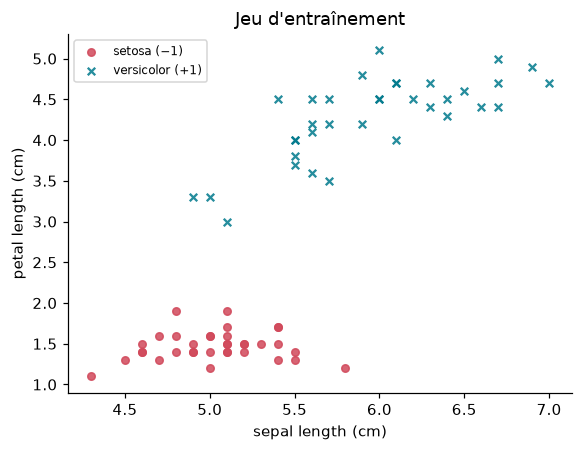

In [7]:
colonnes = [0, 2]
nom_x, nom_y = caracteristiques[colonnes[0]], caracteristiques[colonnes[1]]

binaire = y_iris < 2
X = X_iris[binaire][:, colonnes]
y = np.where(y_iris[binaire] == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2, stratify=y
)
print(f"Entraînement : {len(X_train)} fleurs, dont {(y_train == -1).sum()} setosa")
print(f"Test         : {len(X_test)} fleurs, dont {(y_test == -1).sum()} setosa")


def tracer_points(ax, X, y, titre=None, legende=True):
    for classe, nom in ((-1, "setosa (−1)"), (1, "versicolor (+1)")):
        ax.scatter(
            X[y == classe, 0], X[y == classe, 1], s=24, alpha=0.85,
            color=COULEURS[classe], marker="o" if classe == -1 else "x", label=nom,
        )
    ax.set_xlabel(nom_x)
    ax.set_ylabel(nom_y)
    if titre:
        ax.set_title(titre)
    if legende:
        ax.legend(loc="upper left", fontsize=8)


fig, ax = plt.subplots(figsize=(5.4, 4.2))
tracer_points(ax, X_train, y_train, "Jeu d'entraînement")
fig.tight_layout()
plt.show()


### Lire le découpage

70 fleurs d'entraînement, dont 35 setosa, et 30 fleurs de test, dont 15 setosa. Les deux espèces sont représentées à parts égales des deux côtés.

Les points rouges (setosa) et les croix bleues (versicolor) occupent deux bandes horizontales distinctes : la longueur du pétale suffit presque à elle seule. Le perceptron devra trouver une droite entre les deux.

*Remarque sur le TP d'origine* : la solution traçait les colonnes 0 et 2 mais étiquetait les axes avec les noms des colonnes 2 et 3. Les axes ci-dessus sont tirés des colonnes réellement utilisées.


## 3. Ce que calcule un neurone

Le perceptron reçoit un vecteur $x = (x_1, x_2)$. Il calcule une **somme pondérée** des entrées, plus un **biais** $b$ :

$$
z = w_1 x_1 + w_2 x_2 + b = w \cdot x + b
$$

Puis une **fonction d'activation** transforme $z$ en décision. Pour Rosenblatt, c'est une marche (fonction seuil) :

$$
\hat{y} = \begin{cases} +1 & \text{si } z \ge 0 \\ -1 & \text{sinon} \end{cases}
$$

Géométriquement, les points où $z = 0$ forment une **droite** (un hyperplan en dimension plus grande). D'un côté, le neurone répond +1, de l'autre −1. Le vecteur des poids $w$ est perpendiculaire à cette droite et pointe vers le côté +1. Le biais déplace la droite sans la faire tourner.

Avant tout apprentissage, on peut choisir des poids à la main. Avec $w = (0, 1)$ et $b = -2{,}5$, le neurone calcule $z = \text{longueur du pétale} - 2{,}5$ : c'est un simple seuil à 2,5 cm sur le pétale. Un seuil sur une variable est donc un perceptron dont un poids est nul.


Poids choisis à la main : w = [0. 1.], b = -2.5
Exactitude sur l'entraînement : 1.00


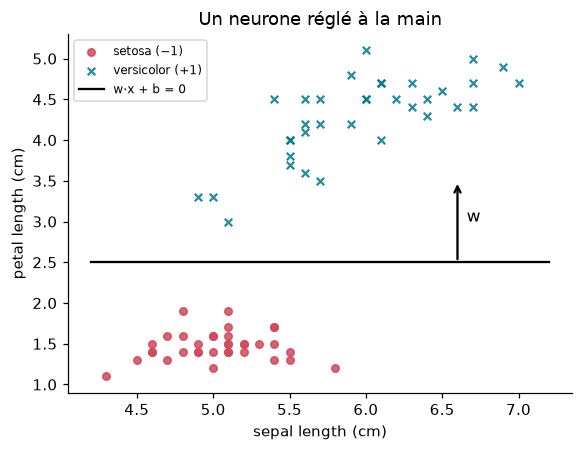

In [9]:
def neurone(X, w, b):
    """Somme pondérée puis marche : renvoie -1 ou +1."""
    z = X @ w + b
    return np.where(z >= 0, 1, -1)


def tracer_droite(ax, w, b, limites_x, **style):
    """Trace la droite w·x + b = 0 dans le plan."""
    xs = np.linspace(*limites_x, 50)
    if abs(w[1]) > 1e-12:
        ax.plot(xs, -(w[0] * xs + b) / w[1], **style)
    elif abs(w[0]) > 1e-12:
        ax.axvline(-b / w[0], **style)


w_main = np.array([0.0, 1.0])
b_main = -2.5
pred = neurone(X_train, w_main, b_main)
print(f"Poids choisis à la main : w = {w_main}, b = {b_main}")
print(f"Exactitude sur l'entraînement : {accuracy_score(y_train, pred):.2f}")

fig, ax = plt.subplots(figsize=(5.4, 4.2))
tracer_points(ax, X_train, y_train, "Un neurone réglé à la main")
tracer_droite(ax, w_main, b_main, (4.2, 7.2), color="black", linewidth=1.5, label="w·x + b = 0")
ax.annotate(
    "", xy=(6.6, 3.5), xytext=(6.6, 2.5),
    arrowprops=dict(arrowstyle="->", color="black", linewidth=1.5),
)
ax.text(6.66, 3.0, "w", fontsize=11)
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()


### Lire le neurone réglé à la main

Le seuil à 2,5 cm classe correctement les 70 fleurs d'entraînement : exactitude **1,00**. La droite est horizontale, parce que le poids du sépale est nul : la longueur du sépale n'intervient pas dans la décision. La flèche $w = (0, 1)$ est perpendiculaire à la droite et pointe vers les versicolor, le côté où $z > 0$.

Ici on a lu le graphique pour régler les poids. Avec 4 caractéristiques, ou 784 pixels pour une image de chiffre, ce n'est plus possible. L'apprentissage consiste à trouver $w$ et $b$ automatiquement, à partir des exemples.


## 4. La règle d'apprentissage de Rosenblatt

Le perceptron parcourt les exemples d'entraînement un par un. Pour chacun, il prédit $\hat{y}$, puis corrige :

$$
\Delta = \eta \,(y - \hat{y}), \qquad w \leftarrow w + \Delta \, x, \qquad b \leftarrow b + \Delta
$$

$\eta$ est le **taux d'apprentissage**. Comme $y$ et $\hat{y}$ valent −1 ou +1, la différence $y - \hat{y}$ ne prend que trois valeurs :

- 0 si la prédiction est juste : **rien ne change** ;
- +2 si le neurone a répondu −1 au lieu de +1 : on ajoute $2\eta x$ aux poids, ce qui augmente $z$ pour cet exemple ;
- −2 dans le cas inverse : on retire $2\eta x$.

Le perceptron n'apprend donc que de ses erreurs. Un passage complet sur les exemples s'appelle une **époque**.

La classe ci-dessous reprend la structure du chapitre 2 de *Python Machine Learning* (Raschka), dont vient le code du TP d'origine. Elle ajoute deux choses utiles pour comprendre : un historique des poids après chaque correction, et un mélange optionnel des exemples à chaque époque.


In [10]:
class Perceptron:
    """Perceptron de Rosenblatt.

    Paramètres
    ----------
    taux : float
        Taux d'apprentissage η.
    epoques : int
        Nombre de passages sur le jeu d'entraînement.
    melanger : bool
        Si vrai, l'ordre des exemples est tiré au hasard à chaque époque.
    poids_initiaux : "zeros" ou "aleatoires"
        Poids de départ. "aleatoires" tire une loi normale d'écart-type 0,01.
    graine : int
        Graine du générateur local.

    Attributs après fit
    -------------------
    w_, b_ : poids et biais appris.
    erreurs_ : nombre de corrections à chaque époque.
    historique_ : liste des (w, b) après chaque correction.
    """

    def __init__(self, taux=0.1, epoques=10, melanger=False, poids_initiaux="zeros", graine=GRAINE):
        self.taux = taux
        self.epoques = epoques
        self.melanger = melanger
        self.poids_initiaux = poids_initiaux
        self.graine = graine

    def somme_ponderee(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.somme_ponderee(X) >= 0.0, 1, -1)

    def fit(self, X, y):
        rng = np.random.default_rng(self.graine)
        if self.poids_initiaux == "zeros":
            self.w_ = np.zeros(X.shape[1])
        else:
            self.w_ = rng.normal(0.0, 0.01, X.shape[1])
        self.b_ = 0.0
        self.erreurs_ = []
        self.historique_ = [(self.w_.copy(), self.b_)]

        for _ in range(self.epoques):
            ordre = rng.permutation(len(X)) if self.melanger else np.arange(len(X))
            corrections = 0
            for i in ordre:
                delta = self.taux * (y[i] - self.predict(X[i]))
                if delta != 0.0:
                    self.w_ = self.w_ + delta * X[i]
                    self.b_ = self.b_ + delta
                    corrections += 1
                    self.historique_.append((self.w_.copy(), self.b_))
            self.erreurs_.append(corrections)
        return self


### Suivre la première époque à la main

Avant de lancer l'entraînement complet, on suit les premières corrections, exemple par exemple, avec $\eta = 0{,}1$ et des poids de départ nuls.


In [11]:
w = np.zeros(2)
b = 0.0
taux = 0.1
print(f"{'n°':>3} {'sépale':>7} {'pétale':>7} {'y':>3} {'z':>7} {'ŷ':>3} {'Δ':>5}   nouveaux w, b")
for i, (xi, cible) in enumerate(zip(X_train, y_train)):
    z = xi @ w + b
    prediction = 1 if z >= 0 else -1
    delta = taux * (cible - prediction)
    if delta != 0:
        w = w + delta * xi
        b = b + delta
    if i < 10 or delta != 0:
        poids = f"w = ({w[0]:+.2f}, {w[1]:+.2f}), b = {b:+.1f}" if delta != 0 else "inchangés"
        print(
            f"{i:3d} {xi[0]:7.1f} {xi[1]:7.1f} {cible:3d} {z:7.2f} {prediction:3d} {delta:5.1f}   {poids}"
        )
print(f"\nFin de la première époque : w = ({w[0]:.2f}, {w[1]:.2f}), b = {b:.1f}")


 n°  sépale  pétale   y       z   ŷ     Δ   nouveaux w, b
  0     5.1     1.9  -1    0.00   1  -0.2   w = (-1.02, -0.38), b = -0.2
  1     5.4     4.5   1   -7.42  -1   0.2   w = (+0.06, +0.52), b = +0.0
  2     6.6     4.4   1    2.68   1   0.0   inchangés
  3     6.2     4.5   1    2.71   1   0.0   inchangés
  4     4.9     1.5  -1    1.07   1  -0.2   w = (-0.92, +0.22), b = -0.2
  5     4.3     1.1  -1   -3.91  -1   0.0   inchangés
  6     5.0     1.2  -1   -4.54  -1   0.0   inchangés
  7     4.8     1.4  -1   -4.31  -1   0.0   inchangés
  8     6.7     5.0   1   -5.26  -1   0.2   w = (+0.42, +1.22), b = +0.0
  9     5.2     1.4  -1    3.89   1  -0.2   w = (-0.62, +0.94), b = -0.2
 11     5.5     3.8   1   -0.04  -1   0.2   w = (+0.48, +1.70), b = +0.0
 14     5.1     1.4  -1    4.83   1  -0.2   w = (-0.54, +1.42), b = -0.2

Fin de la première époque : w = (-0.54, 1.42), b = -0.2


### Lire la trace

Le premier exemple est une setosa. Avec des poids nuls, $z = 0$, et la marche répond +1 (le cas $z \ge 0$). C'est faux : $\Delta = 0{,}1 \times (-1 - 1) = -0{,}2$, et les poids deviennent $-0{,}2 \times (5{,}1 ;\, 1{,}9) = (-1{,}02 ;\, -0{,}38)$.

L'exemple suivant, une versicolor, donne alors $z = -7{,}42$ : nouvelle erreur, dans l'autre sens, et la correction $+0{,}2 \times x$ fait remonter les poids. Les exemples 2 et 3 sont ensuite bien classés : les poids ne bougent pas.

Les corrections alternent ainsi d'une classe à l'autre. Au total, la première époque fait **7** corrections, aux exemples 0, 1, 4, 8, 9, 11 et 14. Après l'exemple 14, plus aucune erreur : la droite finale est atteinte avec $w = (-0{,}54 ;\, 1{,}42)$ et $b = -0{,}2$. Le poids du pétale est positif et plus grand en valeur absolue que celui du sépale : l'algorithme a retrouvé que le pétale est la variable qui compte.

La figure suivante dessine la droite après chacune de ces corrections.


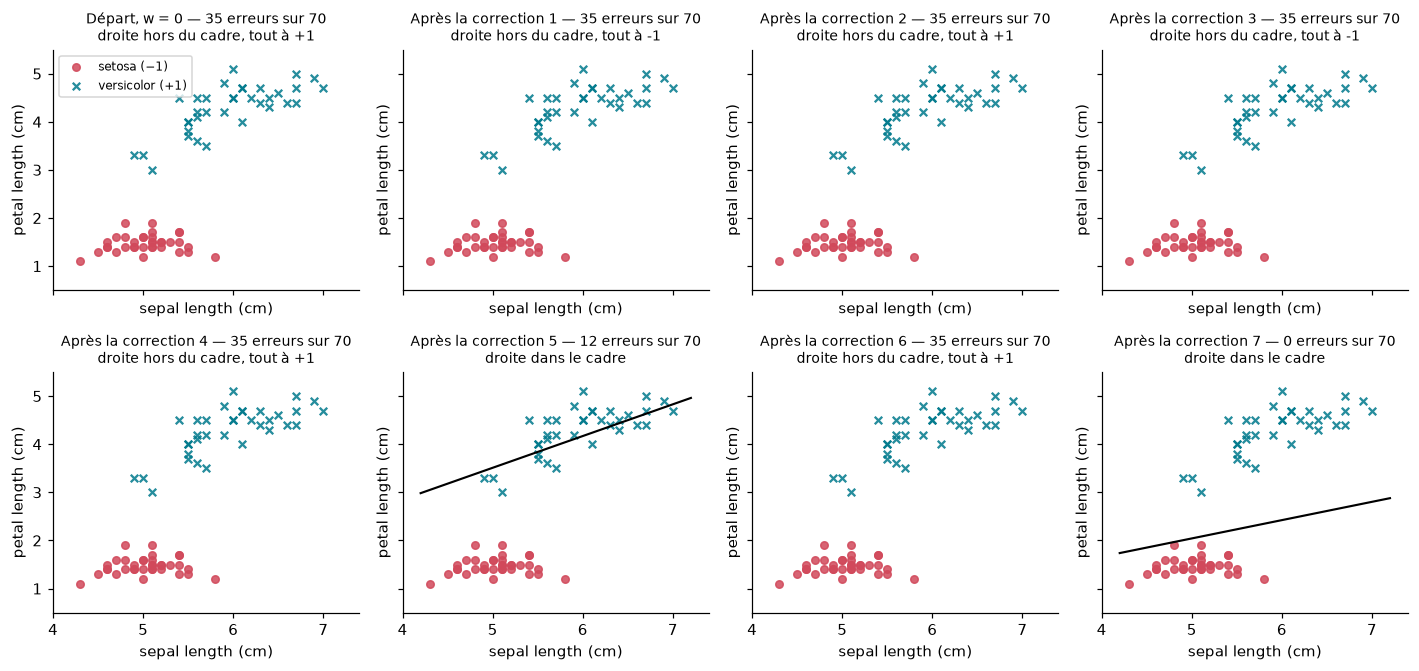

In [12]:
modele = Perceptron(taux=0.1, epoques=10).fit(X_train, y_train)

etapes = modele.historique_
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True)
for k, ax in enumerate(axes.ravel()):
    if k >= len(etapes):
        ax.axis("off")
        continue
    w_k, b_k = etapes[k]
    tracer_points(ax, X_train, y_train, legende=(k == 0))
    predictions = neurone(X_train, w_k, b_k)
    erreurs = int((predictions != y_train).sum())
    if np.all(predictions == predictions[0]):
        etat = f"droite hors du cadre, tout à {predictions[0]:+d}"
    else:
        tracer_droite(ax, w_k, b_k, (4.2, 7.2), color="black", linewidth=1.4)
        etat = "droite dans le cadre"
    titre = "Départ, w = 0" if k == 0 else f"Après la correction {k}"
    ax.set_title(f"{titre} — {erreurs} erreurs sur 70\n{etat}", fontsize=9)
    ax.set_xlim(4.0, 7.4)
    ax.set_ylim(0.5, 5.5)
fig.tight_layout()
plt.show()


### Lire les huit étapes

Au départ, $w = 0$ : pas de droite, et le neurone répond +1 partout. Les 35 setosa sont fausses.

Les quatre premières corrections font basculer la droite d'un bord à l'autre, mais toujours hors du cadre : le neurone répond la même classe pour toutes les fleurs, tantôt −1, tantôt +1, et fait 35 erreurs à chaque fois. La cinquième correction fait enfin entrer la droite dans le nuage (12 erreurs). La sixième la ressort : on revient à 35 erreurs. La septième la place entre les deux espèces, et il n'y a plus d'erreur.

Chaque correction ne regarde **qu'un seul exemple**. Elle corrige ce point, souvent trop fort, et peut abîmer le classement de tous les autres : c'est ce que montre le passage de 12 à 35 erreurs entre la cinquième et la sixième correction. La règle ne garantit pas que chaque pas améliore l'ensemble, seulement qu'elle finit par trouver une séparation si elle existe (section 8).

Ce va-et-vient est l'ancêtre direct de la descente de gradient stochastique qui entraîne les réseaux profonds : une mise à jour par exemple (ou par petit lot), dans la direction qui corrige cet exemple-là.


## 5. Entraîner et évaluer

On regarde maintenant les 10 époques : le nombre de corrections par époque, puis l'exactitude sur le jeu de test, que le modèle n'a jamais vu. On compare enfin avec le `Perceptron` de scikit-learn.


Corrections par époque : [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Poids finaux : w = (-0.54, 1.42), b = -0.2

Exactitude sur l'entraînement : 1.00
Exactitude sur le test        : 1.00
Matrice de confusion (lignes = vérité, colonnes = prédiction, ordre −1 puis +1) :
[[15  0]
 [ 0 15]]

scikit-learn : exactitude test 1.00, w = [-3.1  6.4], b = -1.0, 7 époques


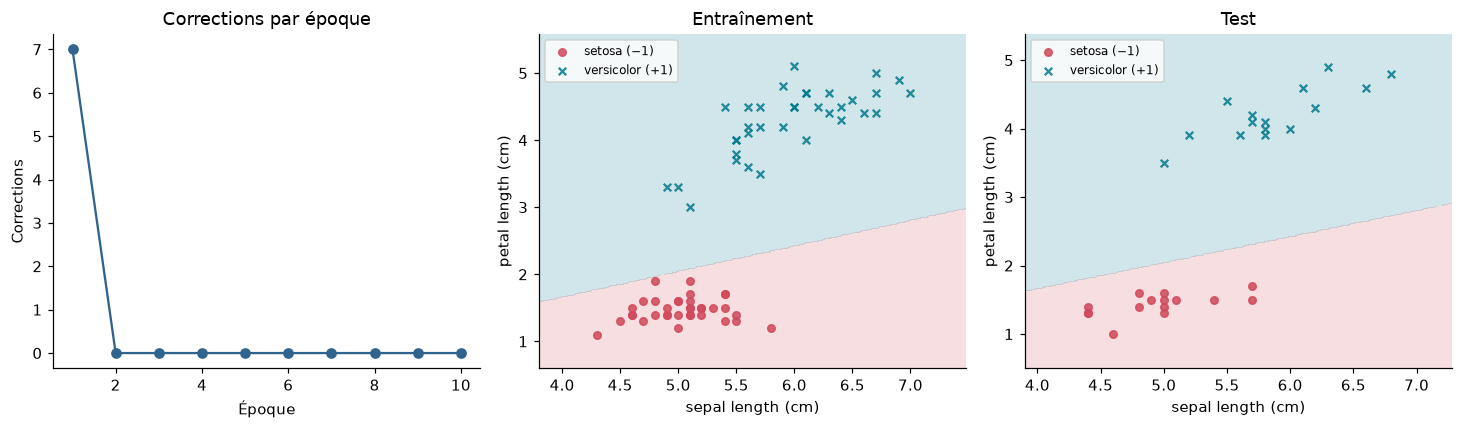

In [13]:
print(f"Corrections par époque : {modele.erreurs_}")
print(f"Poids finaux : w = ({modele.w_[0]:.2f}, {modele.w_[1]:.2f}), b = {modele.b_:.1f}")

y_pred = modele.predict(X_test)
print(f"\nExactitude sur l'entraînement : {accuracy_score(y_train, modele.predict(X_train)):.2f}")
print(f"Exactitude sur le test        : {accuracy_score(y_test, y_pred):.2f}")
print("Matrice de confusion (lignes = vérité, colonnes = prédiction, ordre −1 puis +1) :")
print(confusion_matrix(y_test, y_pred, labels=[-1, 1]))

sklearn_modele = PerceptronSklearn(max_iter=10, random_state=0).fit(X_train, y_train)
print(f"\nscikit-learn : exactitude test {sklearn_modele.score(X_test, y_test):.2f}, "
      f"w = {np.round(sklearn_modele.coef_[0], 2)}, b = {sklearn_modele.intercept_[0]:.1f}, "
      f"{sklearn_modele.n_iter_} époques")


def tracer_regions(ax, predire, X, y, titre, pas=0.02):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, pas), np.arange(y_min, y_max, pas))
    zone = predire(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, levels=[-2, 0, 2], colors=[COULEURS[-1], COULEURS[1]], alpha=0.18)
    tracer_points(ax, X, y, titre)


fig, axes = plt.subplots(1, 3, figsize=(13.4, 4))
axes[0].plot(range(1, len(modele.erreurs_) + 1), modele.erreurs_, marker="o", color="#30638e")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Corrections")
axes[0].set_title("Corrections par époque")
tracer_regions(axes[1], modele.predict, X_train, y_train, "Entraînement")
tracer_regions(axes[2], modele.predict, X_test, y_test, "Test")
fig.tight_layout()
plt.show()


### Lire l'entraînement

Les corrections par époque valent **7**, puis **0** pour les neuf époques suivantes. Une époque sans correction signifie que tous les exemples d'entraînement sont bien classés : la règle ne modifie plus rien, l'apprentissage est terminé. Les époques supplémentaires ne coûtent que du calcul.

L'exactitude vaut **1,00** sur l'entraînement et **1,00** sur le test : les 15 setosa et les 15 versicolor de test sont bien classées, la matrice de confusion n'a que des zéros hors de la diagonale. scikit-learn obtient aussi 1,00, en 7 époques, avec d'autres poids (−3,1 et 6,4 ; biais −1). Il utilise un taux de 1 et mélange les exemples : il trouve une autre droite, tout aussi correcte. La section 7 explique pourquoi plusieurs droites sont possibles.

Un score parfait est normal ici : les deux espèces sont nettement séparées (section 1). Il ne prouve pas que le perceptron est un bon modèle en général, seulement que ce problème-là est facile.

*Remarque sur le TP d'origine* : une cellule calculait un $R^2$ (`r2_score`) sur des étiquettes de classe. Le $R^2$ est une métrique de **régression** : il suppose qu'une erreur de 0 à 2 est pire qu'une erreur de 0 à 1. Entre des espèces, cette distance n'a pas de sens. En classification, on lit l'exactitude, la matrice de confusion, et le F1 par classe quand les classes sont déséquilibrées (ML 1).


## 6. Le taux d'apprentissage

Le TP d'origine invitait à faire varier le taux d'apprentissage $\eta$. On entraîne quatre perceptrons, avec $\eta$ de 0,0001 à 1, d'abord avec des poids de départ nuls, puis avec des poids de départ aléatoires.


In [14]:
print("Poids de départ nuls")
print(f"{'η':>8}  {'corrections par époque':32} {'w':>20} {'b':>9} {'test':>6}")
for taux in (0.0001, 0.01, 0.1, 1.0):
    p = Perceptron(taux=taux, epoques=10).fit(X_train, y_train)
    print(
        f"{taux:8g}  {str(p.erreurs_):32} "
        f"({p.w_[0]:8.4f}, {p.w_[1]:7.4f}) {p.b_:9.4f} {accuracy_score(y_test, p.predict(X_test)):6.2f}"
    )

print("\nPoids de départ aléatoires (écart-type 0,01)")
for taux in (0.0001, 0.01, 1.0):
    p = Perceptron(taux=taux, epoques=10, poids_initiaux="aleatoires", graine=1).fit(X_train, y_train)
    print(f"{taux:8g}  {str(p.erreurs_):32} test {accuracy_score(y_test, p.predict(X_test)):.2f}")


Poids de départ nuls
       η  corrections par époque                              w         b   test
  0.0001  [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]   ( -0.0005,  0.0014)   -0.0002   1.00
    0.01  [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]   ( -0.0540,  0.1420)   -0.0200   1.00
     0.1  [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]   ( -0.5400,  1.4200)   -0.2000   1.00
       1  [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]   ( -5.4000, 14.2000)   -2.0000   1.00

Poids de départ aléatoires (écart-type 0,01)
  0.0001  [6, 0, 0, 0, 0, 0, 0, 0, 0, 0]   test 1.00
    0.01  [7, 5, 0, 0, 0, 0, 0, 0, 0, 0]   test 1.00
       1  [7, 0, 0, 0, 0, 0, 0, 0, 0, 0]   test 1.00


### Lire le taux d'apprentissage

Avec des poids de départ nuls, les quatre taux donnent **exactement** la même suite de corrections (7, puis 0) et la même exactitude. Seuls les poids changent, et ils sont proportionnels au taux : $w = (-0{,}54 ;\, 1{,}42)$ pour $\eta = 0{,}1$, $(-5{,}4 ;\, 14{,}2)$ pour $\eta = 1$.

La raison est dans la règle. Partant de 0, chaque correction ajoute $\pm 2\eta x$ : tous les poids et le biais sont des multiples de $\eta$. Multiplier $w$ et $b$ par une constante positive ne change pas le signe de $w \cdot x + b$, donc ne change aucune prédiction. Pour un perceptron à marche initialisé à zéro, **le taux d'apprentissage ne sert à rien**.

Avec des poids de départ aléatoires, ce n'est plus vrai : $\eta = 0{,}01$ demande deux époques (7, puis 5 corrections) au lieu d'une. Le taux fixe alors la taille des corrections par rapport aux poids initiaux.

Cette insensibilité est propre à la marche. Dès que l'activation est continue (sigmoïde, ReLU) et que l'on minimise une perte par descente de gradient — c'est le cas de tous les réseaux du TP suivant — le taux d'apprentissage devient l'hyperparamètre le plus important : trop petit, l'entraînement n'avance pas ; trop grand, la perte diverge.


## 7. L'ordre des exemples et l'unicité de la frontière

Le perceptron s'arrête dès qu'il ne fait plus d'erreur. Il ne cherche pas la *meilleure* droite, seulement *une* droite qui sépare. Si l'ordre de présentation des exemples change, la suite des corrections change, et la droite finale aussi.

On entraîne trois perceptrons qui ne diffèrent que par la graine du mélange. On trace aussi, en pointillés, la droite d'un SVM linéaire à marge maximale : celle qui s'éloigne le plus des deux nuages.


Graine 1 : corrections [7, 0, 0, 0]…, pente 0.51, test 1.00
Graine 2 : corrections [12, 0, 0, 0]…, pente 0.39, test 1.00
Graine 3 : corrections [14, 3, 2, 0]…, pente 0.49, test 1.00
SVM : pente -0.00, test 1.00


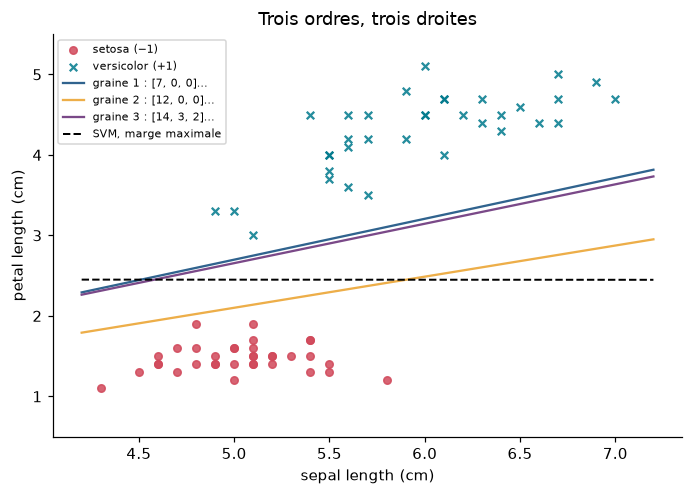

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
tracer_points(ax, X_train, y_train, "Trois ordres, trois droites")
styles = ["#30638e", "#edae49", "#7a4988"]
for graine, couleur in zip((1, 2, 3), styles):
    p = Perceptron(taux=0.1, epoques=10, melanger=True, graine=graine).fit(X_train, y_train)
    tracer_droite(ax, p.w_, p.b_, (4.2, 7.2), color=couleur, linewidth=1.5,
                  label=f"graine {graine} : {p.erreurs_[:3]}…")
    print(
        f"Graine {graine} : corrections {p.erreurs_[:4]}…, "
        f"pente {-p.w_[0] / p.w_[1]:.2f}, test {accuracy_score(y_test, p.predict(X_test)):.2f}"
    )

svm = SVC(kernel="linear", C=1e6).fit(X_train, y_train)
tracer_droite(ax, svm.coef_[0], svm.intercept_[0], (4.2, 7.2),
              color="black", linestyle="--", linewidth=1.3, label="SVM, marge maximale")
print(f"SVM : pente {-svm.coef_[0][0] / svm.coef_[0][1]:.2f}, test {svm.score(X_test, y_test):.2f}")
ax.set_ylim(0.5, 5.5)
ax.legend(loc="upper left", fontsize=7)
fig.tight_layout()
plt.show()


### Lire les trois droites

Les trois perceptrons obtiennent tous l'exactitude maximale sur le test, mais pas avec la même droite : les pentes et les positions diffèrent, et le nombre de corrections nécessaires aussi. Certaines droites passent très près d'un nuage. Une fleur nouvelle, un peu en dehors des points vus, a plus de chances d'être mal classée par une droite qui frôle les données que par une droite placée au milieu.

Le SVM résout exactement ce problème : parmi toutes les droites séparatrices, il choisit celle de **marge maximale** ([ML 0](ML_0_SVM_apprentissage_supervisee.ipynb)). Le perceptron et le SVM linéaire ont la même forme de décision, $\text{signe}(w \cdot x + b)$. Ils diffèrent par le critère d'apprentissage. C'est une idée qui revient sans cesse en deep learning : deux modèles de même architecture peuvent généraliser différemment selon la fonction que l'on optimise.


## 8. Combien d'erreurs ? Convergence et normalisation

Novikoff (1962) a démontré que, si les classes sont séparables, le perceptron converge en un nombre fini de corrections. Notons $R$ la plus grande norme d'un exemple (biais compris, en ajoutant une coordonnée constante égale à 1) et $\gamma$ la marge de la meilleure séparation, c'est-à-dire la distance du point le plus proche à la droite du SVM. Alors le nombre total de corrections vérifie :

$$
\text{corrections} \le \left( \frac{R}{\gamma} \right)^2
$$

La borne dépend du rapport entre la taille des données et l'écart entre les classes. On la calcule sur les mesures en centimètres, puis après **standardisation** : chaque caractéristique centrée et divisée par son écart-type, avec la moyenne et l'écart-type calculés sur l'entraînement uniquement.


In [16]:
def borne_novikoff(X, y):
    """Renvoie R, γ et la borne (R/γ)² pour des données séparables."""
    X_aug = np.hstack([X, np.ones((len(X), 1))])
    svm = SVC(kernel="linear", C=1e6).fit(X, y)
    w_svm = np.r_[svm.coef_[0], svm.intercept_[0]]
    marge = (y * (X_aug @ w_svm)).min() / np.linalg.norm(w_svm)
    rayon = np.linalg.norm(X_aug, axis=1).max()
    return rayon, marge, (rayon / marge) ** 2


normaliseur = StandardScaler().fit(X_train)
X_train_std = normaliseur.transform(X_train)
X_test_std = normaliseur.transform(X_test)

print(f"{'Données':16}{'R':>7}{'γ':>8}{'borne':>9}{'corrections':>13}{'test':>7}")
for nom, Xa, Xb in (("En cm", X_train, X_test), ("Standardisées", X_train_std, X_test_std)):
    rayon, marge, borne = borne_novikoff(Xa, y_train)
    p = Perceptron(taux=0.1, epoques=20).fit(Xa, y_train)
    print(
        f"{nom:16}{rayon:7.2f}{marge:8.3f}{borne:9.0f}{sum(p.erreurs_):13d}"
        f"{accuracy_score(y_test, p.predict(Xb)):7.2f}"
    )


Données               R       γ    borne  corrections   test
En cm              8.52   0.208     1686            7   1.00
Standardisées      2.85   0.363       62            3   1.00


### Lire la borne

En centimètres, $R = 8{,}52$ et $\gamma = 0{,}208$ : la borne garantit au plus **1 686** corrections. Le perceptron en fait **7**. Après standardisation, $R$ tombe à 2,85 et $\gamma$ monte à 0,363 : la borne descend à **62**, et le perceptron ne fait plus que **3** corrections.

La borne est très pessimiste, c'est un pire cas. Mais elle dit dans quel sens agir. Des mesures en centimètres loin de l'origine (le sépale vaut environ 5 cm) gonflent $R$ sans rien ajouter à la séparation. Centrer et réduire ramène les données autour de 0, à des échelles comparables. Pour la même raison, on standardise presque toujours les entrées d'un réseau de neurones, et on normalise les pixels d'une image.

Le normaliseur est ajusté sur l'entraînement seul, puis appliqué au test. L'ajuster sur toutes les données ferait entrer de l'information du test dans le modèle : c'est une **fuite de données**, la même erreur de méthode que choisir un hyperparamètre sur le test.


## 9. Quand les classes se recouvrent : versicolor contre virginica

Le théorème de Novikoff suppose une séparation parfaite. On reprend le problème avec **versicolor (−1)** et **virginica (+1)**, sur la longueur et la largeur du pétale, standardisées. La section 1 a montré que quelques fleurs se mélangent.

On entraîne 50 époques, en notant à la fin de chaque époque le nombre d'erreurs sur tout l'entraînement. Puis on mesure l'exactitude de test qu'on aurait obtenue en arrêtant l'apprentissage après 1, 2, … 50 époques.

On essaie aussi l'algorithme **pocket** (Gallant, 1990) : il garde « dans sa poche » les poids qui ont fait le moins d'erreurs d'entraînement depuis le début, au lieu des derniers poids.


Erreurs d'entraînement en fin d'époque (12 premières) : [9, 5, 5, 7, 10, 7, 10, 7, 10, 8, 10, 8]
Minimum atteint : 5 erreurs sur 70
Exactitude de test selon l'époque d'arrêt : de 0.87 à 0.97, 0.90 après 50 époques
Pocket : 5 erreurs d'entraînement, exactitude de test 0.97


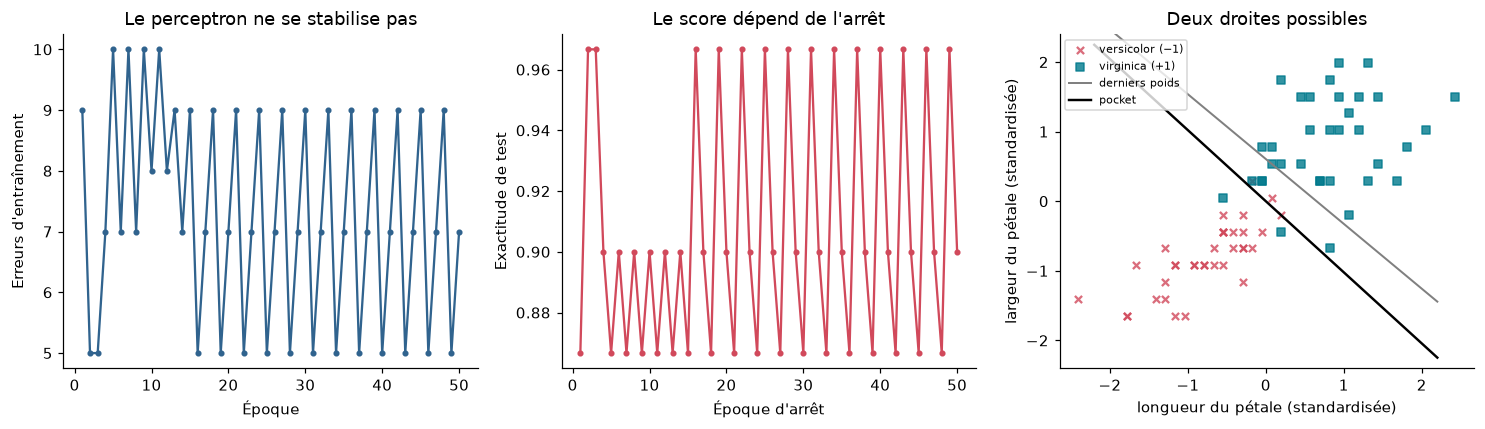


Avec les 4 caractéristiques standardisées :
  minimum d'erreurs d'entraînement : 1 sur 70


In [17]:
paire = y_iris > 0
colonnes_vv = [2, 3]
X_vv = X_iris[paire][:, colonnes_vv]
y_vv = np.where(y_iris[paire] == 1, -1, 1)
Xv_train, Xv_test, yv_train, yv_test = train_test_split(
    X_vv, y_vv, test_size=0.3, random_state=2, stratify=y_vv
)
norm_vv = StandardScaler().fit(Xv_train)
Zv_train, Zv_test = norm_vv.transform(Xv_train), norm_vv.transform(Xv_test)


class PerceptronPocket(Perceptron):
    """Perceptron qui garde les poids ayant le moins d'erreurs d'entraînement."""

    def fit(self, X, y):
        rng = np.random.default_rng(self.graine)
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.erreurs_, self.erreurs_fin_epoque_ = [], []
        meilleur = (np.inf, self.w_.copy(), self.b_)
        for _ in range(self.epoques):
            ordre = rng.permutation(len(X)) if self.melanger else np.arange(len(X))
            corrections = 0
            for i in ordre:
                delta = self.taux * (y[i] - self.predict(X[i]))
                if delta != 0.0:
                    self.w_ = self.w_ + delta * X[i]
                    self.b_ += delta
                    corrections += 1
            self.erreurs_.append(corrections)
            fautes = int((self.predict(X) != y).sum())
            self.erreurs_fin_epoque_.append(fautes)
            if fautes < meilleur[0]:
                meilleur = (fautes, self.w_.copy(), self.b_)
        self.dernier_w_, self.dernier_b_ = self.w_, self.b_
        self.fautes_poche_, self.w_, self.b_ = meilleur
        return self


poche = PerceptronPocket(taux=0.1, epoques=50).fit(Zv_train, yv_train)
print(f"Erreurs d'entraînement en fin d'époque (12 premières) : {poche.erreurs_fin_epoque_[:12]}")
print(f"Minimum atteint : {min(poche.erreurs_fin_epoque_)} erreurs sur {len(yv_train)}")

exactitudes = []
for n in range(1, 51):
    p = Perceptron(taux=0.1, epoques=n).fit(Zv_train, yv_train)
    exactitudes.append(accuracy_score(yv_test, p.predict(Zv_test)))
print(f"Exactitude de test selon l'époque d'arrêt : de {min(exactitudes):.2f} à {max(exactitudes):.2f}, "
      f"{exactitudes[-1]:.2f} après 50 époques")
print(f"Pocket : {poche.fautes_poche_} erreurs d'entraînement, "
      f"exactitude de test {accuracy_score(yv_test, poche.predict(Zv_test)):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4))
axes[0].plot(range(1, 51), poche.erreurs_fin_epoque_, color="#30638e", marker=".")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Erreurs d'entraînement")
axes[0].set_title("Le perceptron ne se stabilise pas")
axes[1].plot(range(1, 51), exactitudes, color="#d1495b", marker=".")
axes[1].set_xlabel("Époque d'arrêt")
axes[1].set_ylabel("Exactitude de test")
axes[1].set_title("Le score dépend de l'arrêt")
for classe, nom, m in ((-1, "versicolor (−1)", "x"), (1, "virginica (+1)", "s")):
    axes[2].scatter(Zv_train[yv_train == classe, 0], Zv_train[yv_train == classe, 1], s=22,
                    alpha=0.8, color=COULEURS[classe], marker=m, label=nom)
tracer_droite(axes[2], poche.dernier_w_, poche.dernier_b_, (-2.2, 2.2), color="gray",
              linewidth=1.3, label="derniers poids")
tracer_droite(axes[2], poche.w_, poche.b_, (-2.2, 2.2), color="black", linewidth=1.6,
              label="pocket")
axes[2].set_xlabel("longueur du pétale (standardisée)")
axes[2].set_ylabel("largeur du pétale (standardisée)")
axes[2].set_ylim(-2.4, 2.4)
axes[2].legend(fontsize=7, loc="upper left")
axes[2].set_title("Deux droites possibles")
fig.tight_layout()
plt.show()

print("\nAvec les 4 caractéristiques standardisées :")
X4 = X_iris[paire]
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y_vv, test_size=0.3, random_state=2, stratify=y_vv)
norm4 = StandardScaler().fit(X4_train)
poche4 = PerceptronPocket(taux=0.1, epoques=50).fit(norm4.transform(X4_train), y4_train)
print(f"  minimum d'erreurs d'entraînement : {poche4.fautes_poche_} sur {len(y4_train)}")


### Lire le recouvrement

Les erreurs d'entraînement ne tombent jamais à zéro : elles oscillent entre 5 et 10 (9, 5, 5, 7, 10, 7, 10…). Il existe toujours un exemple mal classé, donc toujours une correction, et chaque correction déplace la droite au profit d'un point et au détriment d'autres. **La règle de Rosenblatt ne converge pas** quand les classes ne sont pas séparables.

Conséquence pratique : le modèle final dépend de l'époque où l'on s'arrête. L'exactitude de test varie de **0,87 à 0,97** selon ce choix arbitraire, et vaut 0,90 après 50 époques. Le pocket garde les poids qui n'ont fait que **5** erreurs d'entraînement et obtient **0,97** sur le test. Sur la figure de droite, les deux droites traversent la zone où les espèces se mélangent ; elles ont presque la même orientation, mais la droite pocket est décalée vers les versicolor. Aucune des deux ne peut classer tous les points : seul le nombre d'erreurs change.

Avec les quatre caractéristiques, le meilleur passage ne fait plus qu'**1** erreur d'entraînement : ajouter des variables utiles rapproche le problème de la séparabilité. Ce n'est pas toujours vrai — ajouter du bruit ne sépare rien — mais c'est la logique des couches cachées du TP suivant : construire de nouvelles variables où les classes se séparent mieux.

Remarque de méthode : choisir l'époque d'arrêt en regardant la courbe de test, comme on vient de le faire pour l'illustrer, serait tricher. En pratique, on la choisit sur un jeu de **validation** séparé, ou par validation croisée. C'est le principe de l'*early stopping* utilisé pour entraîner les réseaux profonds.


## 10. La limite : le XOR

En 1969, Minsky et Papert ont montré qu'un perceptron seul ne peut pas apprendre certaines fonctions très simples. L'exemple classique est le **OU exclusif** (XOR) : la réponse vaut +1 si une seule des deux entrées vaut 1.

| $x_1$ | $x_2$ | ET | OU | XOR |
|---|---|---|---|---|
| 0 | 0 | −1 | −1 | −1 |
| 0 | 1 | −1 | +1 | +1 |
| 1 | 0 | −1 | +1 | +1 |
| 1 | 1 | +1 | +1 | −1 |

On entraîne un perceptron sur chacune des trois fonctions, puis un petit réseau à **une couche cachée** de 4 neurones (`MLPClassifier`) sur le XOR.


ET   corrections par époque : [2, 3, 3, 0, 0, 0, 0, 0]…  erreurs finales : 0 sur 4
OU   corrections par époque : [2, 2, 1, 0, 0, 0, 0, 0]…  erreurs finales : 0 sur 4
XOR  corrections par époque : [3, 3, 4, 4, 4, 4, 4, 4]…  erreurs finales : 2 sur 4
XOR, réseau à une couche cachée de 4 neurones : 0 erreur sur 4


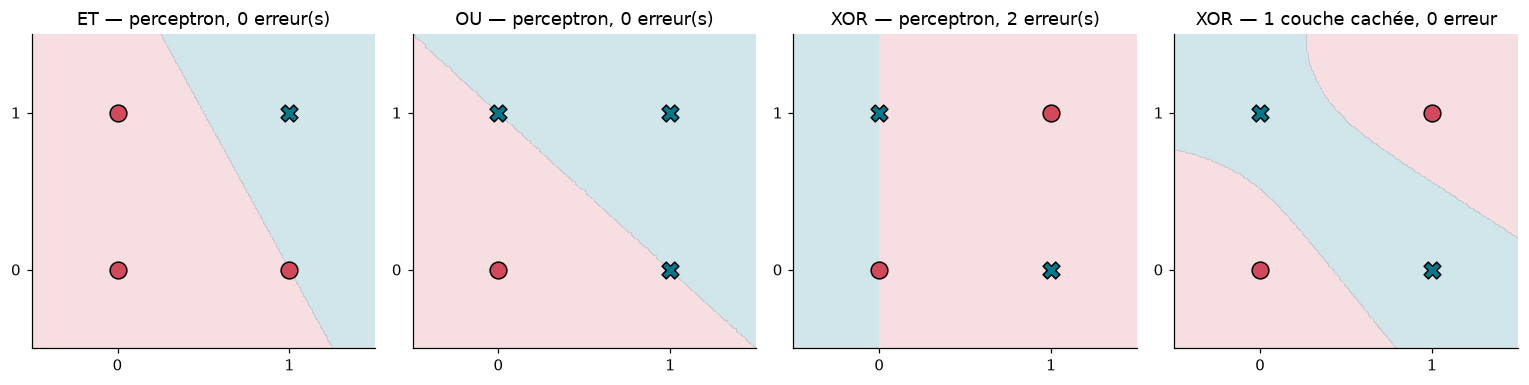

In [18]:
X_logique = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
fonctions = {
    "ET": np.array([-1, -1, -1, 1]),
    "OU": np.array([-1, 1, 1, 1]),
    "XOR": np.array([-1, 1, 1, -1]),
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (nom, cible) in zip(axes, fonctions.items()):
    p = Perceptron(taux=0.1, epoques=20).fit(X_logique, cible)
    fautes = int((p.predict(X_logique) != cible).sum())
    print(f"{nom:4} corrections par époque : {p.erreurs_[:8]}…  erreurs finales : {fautes} sur 4")
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    zone = p.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zone, levels=[-2, 0, 2], colors=[COULEURS[-1], COULEURS[1]], alpha=0.18)
    for classe in (-1, 1):
        ax.scatter(*X_logique[cible == classe].T, s=120, color=COULEURS[classe],
                   marker="o" if classe == -1 else "X", edgecolor="black")
    ax.set_title(f"{nom} — perceptron, {fautes} erreur(s)")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

reseau = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs",
                       random_state=0, max_iter=2000).fit(X_logique, fonctions["XOR"])
fautes_reseau = int((reseau.predict(X_logique) != fonctions["XOR"]).sum())
print(f"XOR, réseau à une couche cachée de 4 neurones : {fautes_reseau} erreur sur 4")
zone = reseau.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[3].contourf(xx, yy, zone, levels=[-2, 0, 2], colors=[COULEURS[-1], COULEURS[1]], alpha=0.18)
for classe in (-1, 1):
    axes[3].scatter(*X_logique[fonctions["XOR"] == classe].T, s=120, color=COULEURS[classe],
                    marker="o" if classe == -1 else "X", edgecolor="black")
axes[3].set_title(f"XOR — 1 couche cachée, {fautes_reseau} erreur")
axes[3].set_xticks([0, 1])
axes[3].set_yticks([0, 1])
fig.tight_layout()
plt.show()


### Lire le XOR

Le ET et le OU sont appris en 3 époques, puis plus aucune correction : une droite sépare le coin (1, 1) des trois autres pour le ET, le coin (0, 0) des trois autres pour le OU.

Le XOR n'est jamais appris. Les corrections ne s'arrêtent pas (3, 3, puis 4 à chaque époque), et la droite finale se trompe sur 2 des 4 points. Aucune droite ne peut mettre (0, 1) et (1, 0) d'un côté, (0, 0) et (1, 1) de l'autre : les deux classes sont sur les deux diagonales d'un carré. Ce n'est pas un problème d'apprentissage, c'est une limite de ce que le modèle peut représenter.

Le réseau à une couche cachée classe les quatre points sans erreur. Sa région +1 n'est plus un demi-plan, c'est une bande entre deux frontières. Chaque neurone caché trace sa propre droite, et le neurone de sortie combine leurs réponses. Empiler des neurones avec une activation non linéaire, c'est le **perceptron multicouche** (MLP) du TP suivant, entraîné par rétropropagation du gradient plutôt que par la règle de Rosenblatt.


## 11. Trois classes et la question du découpage

Un perceptron répond oui ou non. Pour trois espèces, scikit-learn entraîne un perceptron par espèce, « cette espèce contre les deux autres » (**un-contre-tous**), puis choisit l'espèce dont la somme pondérée $w \cdot x + b$ est la plus grande.

On utilise les quatre caractéristiques, standardisées dans un `Pipeline` pour que le normaliseur soit réajusté à chaque découpage. On compare un découpage unique, celui utilisé jusqu'ici, avec une validation croisée en 5 plis.


In [19]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=2, stratify=y_iris
)
modele3 = make_pipeline(StandardScaler(), PerceptronSklearn(max_iter=100, random_state=0))
modele3.fit(X3_train, y3_train)
y3_pred = modele3.predict(X3_test)
print(f"Découpage unique (random_state=2) : exactitude {accuracy_score(y3_test, y3_pred):.2f}")
print(confusion_matrix(y3_test, y3_pred))

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(modele3, X_iris, y_iris, cv=plis)
print(f"\nValidation croisée, 5 plis : {np.round(scores, 2)}")
print(f"Moyenne {scores.mean():.2f}, écart-type {scores.std():.2f}")


Découpage unique (random_state=2) : exactitude 1.00
[[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]

Validation croisée, 5 plis : [1.   0.77 0.83 0.83 0.87]
Moyenne 0.86, écart-type 0.08


### Lire les trois classes

Sur le découpage unique, l'exactitude vaut **1,00** et la matrice de confusion est parfaitement diagonale. Avec la validation croisée, les cinq plis donnent **1,00 ; 0,77 ; 0,83 ; 0,83 ; 0,87**, soit **0,86** en moyenne.

Le score de 1,00 n'était pas faux, il était chanceux : sur 45 fleurs de test, quelques versicolor et virginica difficiles peuvent tomber toutes d'un côté du découpage. La validation croisée fait tourner le jeu de test sur toutes les fleurs et montre la vraie dispersion du résultat. Avec un jeu de données petit, un seul découpage peut faire gagner ou perdre plus de 20 points d'exactitude.

Les erreurs viennent du sous-problème versicolor contre virginica, qui n'est pas séparable (section 9) : un perceptron qui n'a pas convergé rend des poids qui dépendent de l'arrêt et des fleurs présentes dans chaque pli.


## 12. Bilan — ce qu'un ingénieur IA retient du perceptron

### Ce que le perceptron est

| Élément | Perceptron (ce TP) | Réseaux de neurones (TP suivants) |
|---|---|---|
| Calcul d'un neurone | $w \cdot x + b$ | Identique |
| Activation | Marche, sortie −1 ou +1 | Continue et dérivable : sigmoïde, tanh, ReLU |
| Ce qu'on minimise | Rien d'explicite : on corrige chaque erreur | Une fonction de perte (entropie croisée, erreur quadratique) |
| Mise à jour | $w \leftarrow w + \eta (y - \hat{y}) x$, sur les erreurs seulement | $w \leftarrow w - \eta \nabla_w \text{perte}$, sur tous les exemples |
| Rôle du taux $\eta$ | Aucun si les poids partent de 0 (§6) | Hyperparamètre central |
| Frontière | Une droite, n'importe laquelle qui sépare (§7) | Courbe, construite par les couches cachées (§10) |
| Classes non séparables | Ne converge pas, dépend de l'arrêt (§9) | La perte se minimise quand même |

### Les réflexes de méthode vus ici

1. **Regarder les données avant le modèle** : taille, valeurs manquantes, équilibre des classes, nuages de points (§1). On y a vu d'avance quelle paire d'espèces serait facile et laquelle ne le serait pas.
2. **Séparer entraînement et test avant tout ajustement**, en stratifiant (§2), et ajuster le normaliseur sur l'entraînement seul (§8).
3. **Choisir une métrique de classification** : exactitude et matrice de confusion, pas un $R^2$ (§5).
4. **Se méfier d'un score parfait**, ou d'un score sur un seul découpage : la validation croisée a fait passer 1,00 à 0,86 (§11).
5. **Fixer les graines** pour que chaque comparaison soit reproductible, et changer une seule chose à la fois (§6, §7).
6. **Standardiser les entrées** : cela réduit la borne de convergence de 1 686 à 62 corrections, et cela reste vrai pour les réseaux profonds (§8).
7. **Ne pas choisir l'arrêt ou un hyperparamètre sur le test** : utiliser un jeu de validation (§9).
8. **Reconnaître une limite de représentation** : quand aucune droite ne peut séparer les classes, aucun réglage du perceptron ne suffira (§10). Il faut changer de modèle ou de variables.

### Pour s'entraîner

1. Reprendre la section 5 avec une seule caractéristique, puis trois, puis quatre. À partir de combien de variables le nombre de corrections cesse-t-il de baisser ?
2. Remplacer la marche par une sigmoïde dans `predict`, et la règle par une descente de gradient sur l'erreur quadratique (c'est l'**Adaline** de Widrow et Hoff, au chapitre 2 de Raschka). Le taux d'apprentissage reprend-il de l'importance ?
3. Dans la section 9, choisir l'époque d'arrêt par validation croisée sur l'entraînement seulement, puis mesurer le test une seule fois.
4. Construire à la main un réseau à deux neurones cachés qui calcule le XOR : un neurone OU, un neurone ET, et une sortie « OU et pas ET ». Vérifier ses quatre réponses.


### Sources

- F. Rosenblatt, « The perceptron: a probabilistic model for information storage and organization in the brain », *Psychological Review*, 65(6), 1958. [doi:10.1037/h0042519](https://doi.org/10.1037/h0042519)
- A. B. J. Novikoff, « On convergence proofs on perceptrons », *Symposium on the Mathematical Theory of Automata*, 1962 — théorème de convergence de la section 8.
- M. Minsky, S. Papert, *Perceptrons: An Introduction to Computational Geometry*, MIT Press, 1969 — limite du XOR.
- S. I. Gallant, « Perceptron-based learning algorithms », *IEEE Transactions on Neural Networks*, 1(2), 1990. [doi:10.1109/72.80230](https://doi.org/10.1109/72.80230) — algorithme pocket.
- R. A. Fisher, « The use of multiple measurements in taxonomic problems », *Annals of Eugenics*, 7(2), 1936. [doi:10.1111/j.1469-1809.1936.tb02137.x](https://doi.org/10.1111/j.1469-1809.1936.tb02137.x)
- Jeu de données Iris : [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris) ; [Iris de Fisher](https://fr.wikipedia.org/wiki/Iris_de_Fisher), Wikipédia.
- S. Raschka, V. Mirjalili, *Python Machine Learning*, chapitre 2 — classe `Perceptron` et Adaline. [Code du chapitre 2](https://github.com/rasbt/python-machine-learning-book-3rd-edition/tree/master/ch02)
- I. Goodfellow, Y. Bengio, A. Courville, *Deep Learning*, MIT Press, 2016, chapitre 6 — le XOR résolu par un réseau à une couche cachée. [Chapitre en ligne](https://www.deeplearningbook.org/contents/mlp.html)
- [Documentation de `sklearn.linear_model.Perceptron`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html)
- [Perceptron](https://fr.wikipedia.org/wiki/Perceptron), Wikipédia.

### Limites

Iris est petit (150 fleurs) et presque séparable : c'est un bon terrain pour comprendre, pas pour juger un modèle. Les graines, le découpage `random_state=2` et les 10 ou 50 époques sont fixés pour que les chiffres du texte soient reproductibles ; d'autres valeurs changeraient les nombres de corrections et, en section 9, l'exactitude de test. La règle de Rosenblatt n'est plus utilisée telle quelle : on la garde pour sa clarté, et parce que la descente de gradient du TP suivant en est la généralisation.
